# 235. FUN Botryllus proteome against human immune genes and HLA, every alphabet at the bits of protein20 k = 7

**Question.** [Notebook 234](234_kmerseek_fun_botryllus_immune_hla_19_alphabets.ipynb) searched
the 45,339 FUN Botryllus proteins with 19 kmerseek alphabets, each at the k carrying at least
24 bits per k-mer, and found no MHC-like candidate. Here each alphabet runs at the k carrying
at least the 28.45 bits of protein20 at k = 7, the usual protein k-mer size, with bits counted
from Swiss-Prot residue frequencies. Longer k-mers give fewer chance matches. Does any FUN
protein now match an HLA groove or Ig-like domain?

**Decision this informs.** Whether the "no MHC-like candidate from kmerseek" verdict of
notebooks 232 to 234 holds at the k of protein20 k = 7, or whether a FUN protein goes
forward to structure comparison.

At these k, three alphabets give too few chance matches for kmerseek to fit E-values, even
with 19,000 calibration proteins. They were searched without extension and are judged by
the second rule below, in their own section (section 6).

The decision rules, copied from `235_decision_rule.md`, which was committed before any
result of this run was read:

Run: kmerseek 0.4.0, FUN Botryllus proteome (45,339 proteins) against human GENCODE v49
canonical (19,429 proteins), each of 19 alphabets at the k carrying at least the bits of
protein20 k = 7 (28.45 bits, Swiss-Prot 2026_03 residue frequencies; `235_arms.tsv`).

**Alphabets with E-values (the run extends matches and fits E-values)**

The rule of notebooks 232 to 234, unchanged. A FUN protein is an MHC-like candidate if, in
any alphabet, it matches an HLA gene at E ≤ 0.001 and the matched part of the HLA protein
is the peptide-binding groove (class I α1/α2, class II α1/β1) or the Ig-like domain. A
match only to the transmembrane helix or the signal peptide is not MHC evidence. Agreement
between alphabets is not evidence on its own.

**Alphabets without E-values (fallback)**

If an alphabet's E-value fit fails even with 19,000 calibration sequences (job 49956388),
it is searched without extension (`--extend-mismatch-penalty 0`), so its matches have no
E-value, only kmerseek's region p-value (the chance of that many shared k-mers). These
alphabets are reported in their own section, never pooled with the E-value alphabets.

The region p-value alone is not enough: in notebooks 233 and 234, unrelated charged
stretches got p = 0. So a FUN protein is an MHC-like candidate from such an alphabet only
if one match passes all three:

1. region p-value below 0.05 / 880,891,431 (the protein pairs one alphabet compares);
2. the matched part of the HLA protein is the groove or the Ig-like domain (as above);
3. the two stretches carry the same amino acid at more positions than unrelated
   sequences would, with the chance level computed within each letter class
   (`hla_utils.same_residue_vs_chance_in_class`), at a chance below 0.05 divided by the
   number of matches passing 1 and 2 in that alphabet.

If no match passes, the verdict of notebooks 232 to 234 (no MHC-like candidate from
kmerseek) holds for that alphabet too.

**Data.**

* Tool: kmerseek 0.4.0, the alphabets, mismatch penalties and X-drops of notebook 233, with
  the k of `235_arms.tsv` (from `235_plan_arms.py`). Scaled = 1, low-complexity k-mers removed.
* Query: the 45,339 FUN Botryllus proteins of notebook 234 (cleaned by
  `234_prepare_fun_proteome.py`).
* Target database: 19,429 human GENCODE v49 canonical proteins, as in notebooks 233 and 234.
* Run: Sherlock, 28 Oct 2026 (`235_submit_protein20_k7_swissprot.sh`). Arrays 49951877 and
  49951880 ran all 19 alphabets; job 49957853 recalibrated six alphabets whose fit had failed,
  with 19,000 human proteins; job 49956831 searched the same six without extension; job
  49956389 kept the matches to human immune genes (QuickGO GO:0002376 and the terms below it).
  HLA protein parts come from UniProt (`hla_utils.py`).
* E = inf: kmerseek found shared k-mers but did not extend them into an alignment, so no
  E-value exists. For alphabets with E-values these are in section 5.

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import pubfig as pf
from hla_utils import (KNOWN_IMMUNE_FAMILY_PATTERN, PART_COLOUR, PART_MARKER, HlaParts, load_immune_genes,
                       match_line, same_residue_vs_chance, same_residue_vs_chance_in_class, with_gene_columns)

pf.use_style()
pl.Config.set_tbl_rows(80)
pl.Config.set_tbl_width_chars(220)
pl.Config.set_tbl_cols(-1)
pl.Config.set_fmt_str_lengths(60)

RUN_DIR = Path.home() / "data/botryllus/kmerseek-0.4-alphabets-fun-k7"
QUERY_TARGET_LINE = "query: FUN Botryllus proteins (45,339); target: human GENCODE v49 canonical (19,429)"
MAX_EVALUE = 10
STRICT_EVALUE = 1e-3
EVALUE_CUTOFFS = [10, 1, STRICT_EVALUE]
ZERO_X = 0.5  # where a count of 0 is drawn on a log axis, as a grey x
N_PAIRS = 45_339 * 19_429  # Botryllus proteins x human proteins: tests per alphabet
P_THRESHOLD = 0.05 / N_PAIRS  # rule 1 for alphabets without E-values
GROOVE_OR_IG = ["peptide-binding groove", "Ig-like domain"]
OUT_DIR = Path("235_outputs")
FIG_DIR = Path("../figures/235")
for d in (OUT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

arms = pl.read_csv("235_arms.tsv", separator="\t")
# Alphabets grouped by class count, with a gap between groups on every figure.
GROUPS = [("2-3 classes", 2, 3), ("4-8 classes", 4, 8), ("12-18 classes", 12, 18), ("20 classes", 20, 20)]
arms = arms.with_columns(
    pl.when(pl.col("n_classes") <= 3).then(0).when(pl.col("n_classes") <= 8).then(1)
    .when(pl.col("n_classes") <= 18).then(2).otherwise(3).alias("group")
).sort("group", "n_classes", "alphabet")
K_OF = dict(zip(arms["alphabet"], arms["ksize"]))


def tag(alphabet: str) -> str:
    return f"{alphabet}.k{K_OF[alphabet]}.scaled1.lcremoved"


# An alphabet has E-values when its extended search ran (an immune file without ".noext").
# The others were searched only without extension. A ".noext" file of an alphabet that has
# E-values (the fallback ran before the recalibration finished) is not used.
arms = arms.with_columns(pl.col("alphabet").map_elements(
    lambda a: (RUN_DIR / "immune" / f"{tag(a)}.immune.evalue_le_10.csv.gz").exists(),
    return_dtype=pl.Boolean).alias("has_evalues"))
ALL_ALPHABETS = arms["alphabet"].to_list()
ALPHABETS = arms.filter("has_evalues")["alphabet"].to_list()  # judged by the E-value rule
NOEXT_ALPHABETS = arms.filter(~pl.col("has_evalues"))["alphabet"].to_list()  # judged by the p-value rule
assert all((RUN_DIR / "immune" / f"{tag(a)}.noext.immune.evalue_inf.hla.csv.gz").exists() for a in NOEXT_ALPHABETS)
Y_OF, y = {}, 0
for g in range(len(GROUPS)):
    for a in arms.filter(pl.col("group") == g)["alphabet"]:
        Y_OF[a] = y
        y += 1
    y += 0.8  # gap between groups
LABEL_OF = {a: f"{a}, k = {K_OF[a]}" for a in ALL_ALPHABETS}
TOOL_LINE = (f"kmerseek 0.4.0, {len(ALL_ALPHABETS)} alphabets at ≥ 28.45 bits per k-mer (protein20 k = 7), "
             "scaled = 1, low-complexity k-mers removed")


def with_fun_name(frame: pl.DataFrame) -> pl.DataFrame:
    """Add fun_name, the gene name funannotate gave the Botryllus protein (FUN000002_NLRC5 ->
    NLRC5; FUN000051_GALNT6-T2 -> GALNT6), null when the name is only the FUN ID."""
    name = pl.col("query_name").str.extract(r"^FUN\d+_(.+?)(?:-T\d+)?$")
    return frame.with_columns(pl.when(name.str.starts_with("FUN")).then(None).otherwise(name).alias("fun_name"))


def alphabet_axis(ax) -> None:
    """One row per alphabet, grouped by class count, a guide line from each tick."""
    ax.set_yticks([Y_OF[a] for a in ALL_ALPHABETS], [LABEL_OF[a] for a in ALL_ALPHABETS])
    for a in ALL_ALPHABETS:
        ax.axhline(Y_OF[a], color="#dddddd", linewidth=0.3, zorder=0)
    ax.set_ylim(max(Y_OF.values()) + 0.6, -0.6)


def mark_no_evalues(ax, x: float) -> None:
    """Write 'no E-value fit' in the rows of the alphabets searched without extension."""
    for a in NOEXT_ALPHABETS:
        ax.text(x, Y_OF[a], "no E-value fit (section 6)", va="center", fontsize=5, color=pf.GREY)


def read_hla_inf(path: Path) -> pl.DataFrame:
    """Unextended matches to HLA genes, as the summary on Sherlock wrote them."""
    return with_gene_columns(pl.read_csv(path, columns=COLUMNS, schema_overrides=COLUMN_TYPES))


COLUMNS = ["query_name", "target_name", "region_evalue", "region_ka_bits", "region_tail_probability",
           "region_length", "region_n_shared_kmers", "region_start", "region_end", "target_start",
           "target_end", "region_subseq", "target_subseq"]
COLUMN_TYPES = {"query_name": pl.String, "target_name": pl.String, "region_evalue": pl.Float64,
                "region_ka_bits": pl.Float64, "region_tail_probability": pl.Float64, "region_length": pl.Int64,
                "region_n_shared_kmers": pl.Int64, "region_start": pl.Int64, "region_end": pl.Int64,
                "target_start": pl.Int64, "target_end": pl.Int64, "region_subseq": pl.String, "target_subseq": pl.String}

immune_genes = load_immune_genes()
print(f"{len(ALPHABETS)} alphabets with E-values; {len(NOEXT_ALPHABETS)} searched without extension: "
      f"{', '.join(NOEXT_ALPHABETS)}; {len(immune_genes):_} human immune gene symbols")
print(arms.drop("group"))

16 alphabets with E-values; 3 searched without extension: hp_kyte_doolittle2, gbmr7, hsdm17; 2_634 human immune gene symbols
shape: (19, 8)
┌──────────────────────────┬───────────┬───────────────────┬───────┬───────────────┬─────────┬───────┬─────────────┐
│ alphabet                 ┆ n_classes ┆ bits_per_position ┆ ksize ┆ bits_per_kmer ┆ penalty ┆ xdrop ┆ has_evalues │
│ ---                      ┆ ---       ┆ ---               ┆ ---   ┆ ---           ┆ ---     ┆ ---   ┆ ---         │
│ str                      ┆ i64       ┆ f64               ┆ i64   ┆ f64           ┆ f64     ┆ f64   ┆ bool        │
╞══════════════════════════╪═══════════╪═══════════════════╪═══════╪═══════════════╪═════════╪═══════╪═════════════╡
│ hp_kyte_doolittle2       ┆ 2         ┆ 0.9235            ┆ 31    ┆ 28.63         ┆ 1.57    ┆ 6.28  ┆ false       │
│ hp_lehninger2            ┆ 2         ┆ 0.9955            ┆ 29    ┆ 28.87         ┆ 1.51    ┆ 6.03  ┆ true        │
│ hp_lehninger_c_nonpolar2 ┆ 2         ┆ 

## 1. The runs: E-value fits, run time, and how many matches kmerseek did not extend

In [2]:
runs = []
for a in ALL_ALPHABETS:
    noext = a in NOEXT_ALPHABETS
    s = json.loads((RUN_DIR / "evalue_le_10" / f"{tag(a)}{'.noext' if noext else ''}.summary.json").read_text())
    # the fit used 200 human proteins when the index was built, else a recalibration with 1,000, then 19,000
    retry19000 = (RUN_DIR / "ka_survival" / f"{tag(a)}.retry19000.csv").exists()
    if noext:
        queries, fit_log = None, None
    elif s["fitted_first"]:
        queries, fit_log = 200, f"{tag(a)}.index.log"
    elif retry19000:
        queries, fit_log = 19_000, f"{tag(a)}.retry19000.calibrate.log"
    else:
        queries, fit_log = 1_000, f"{tag(a)}.calibrate.log"
    log = (RUN_DIR / "logs" / fit_log).read_text() if fit_log else ""
    # the fitted slope, and the slope the closed form gives at the database's match probability;
    # a slope near 0 makes every E-value about the same, whatever the score
    slope = re.search(r"fitted now: .*?slope ([-0-9.]+) per nat.*?closed form ([-0-9.]+) at", log)
    runs.append({
        "alphabet": a, "n_classes": s["n_classes"], "ksize": int(s["ksize"]), "bits_per_kmer": float(s["bits_per_kmer"]),
        "extension": not noext, "fit_from_n_human_proteins": queries,
        "fit_slope": float(slope[1]) if slope else None, "closed_form_slope": float(slope[2]) if slope else None,
        # kmerseek's fit log warns when the fit has few score bins
        "fit_warning_few_bins": "WARNING: the fit has only" in log,
        "search_minutes": round(s["search_s"] / 60, 1),
        "n_matches": s["n_matches"], "n_evalue_le_10": s["n_evalue_le_10_or_inf"] - s["n_evalue_inf"],
        "n_evalue_inf": s["n_evalue_inf"],
    })
runs = pl.DataFrame(runs).with_columns(
    (pl.col("n_evalue_inf") / (pl.col("n_evalue_le_10") + pl.col("n_evalue_inf"))).alias("fraction_inf"))
runs.write_csv(OUT_DIR / "235_runs_kmerseek_botryllus_vs_gencode_19_alphabets.csv")
print(runs)

shape: (19, 14)
┌────────────────────┬───────────┬───────┬───────────────┬───────────┬────────────────────┬───────────┬───────────────────┬────────────────────┬────────────────┬───────────┬────────────────┬──────────────┬──────────────┐
│ alphabet           ┆ n_classes ┆ ksize ┆ bits_per_kmer ┆ extension ┆ fit_from_n_human_p ┆ fit_slope ┆ closed_form_slope ┆ fit_warning_few_bi ┆ search_minutes ┆ n_matches ┆ n_evalue_le_10 ┆ n_evalue_inf ┆ fraction_inf │
│ ---                ┆ ---       ┆ ---   ┆ ---           ┆ ---       ┆ roteins            ┆ ---       ┆ ---               ┆ ns                 ┆ ---            ┆ ---       ┆ ---            ┆ ---          ┆ ---          │
│ str                ┆ str       ┆ i64   ┆ f64           ┆ bool      ┆ ---                ┆ f64       ┆ f64               ┆ ---                ┆ f64            ┆ i64       ┆ i64            ┆ i64          ┆ f64          │
│                    ┆           ┆       ┆               ┆           ┆ i64                ┆         

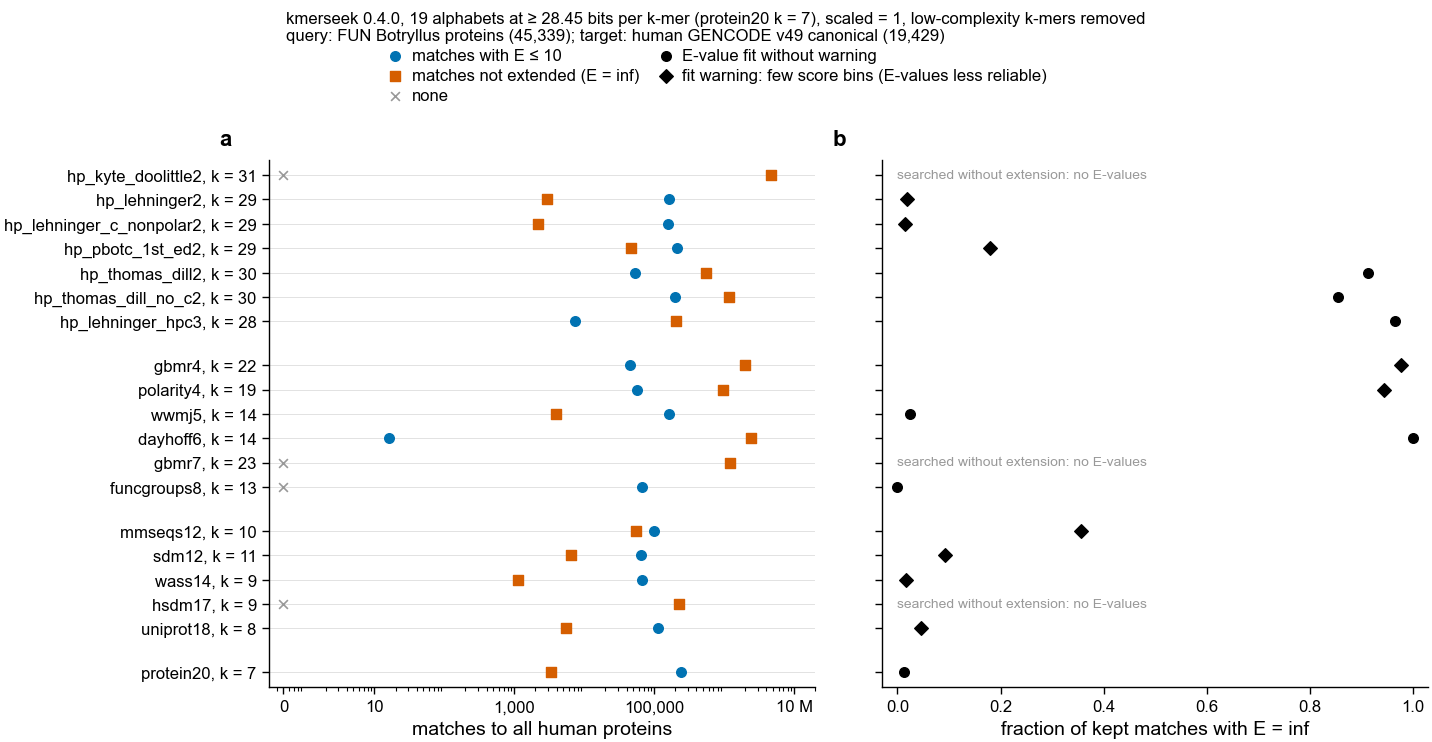

In [3]:
fig, (ax_a, ax_b) = pf.figure(pf.TWO_COLUMN_MM, 95, ncols=2, sharey=True)
for a in ALL_ALPHABETS:
    r = runs.filter(pl.col("alphabet") == a).row(0, named=True)
    for n, colour, marker in [(r["n_evalue_le_10"], pf.OKABE_ITO["blue"], "o"),
                              (r["n_evalue_inf"], pf.OKABE_ITO["vermillion"], "s")]:
        if n > 0:
            ax_a.scatter(n, Y_OF[a], color=colour, marker=marker, s=12, zorder=3)
        else:
            ax_a.scatter(ZERO_X, Y_OF[a], color=pf.GREY, marker="x", s=10, linewidths=0.6, zorder=2)
    if r["extension"]:
        ax_b.scatter(r["fraction_inf"], Y_OF[a], color="black", s=12, zorder=3,
                     marker="D" if r["fit_warning_few_bins"] else "o")
    else:
        ax_b.text(0, Y_OF[a], "searched without extension: no E-values", va="center", fontsize=5, color=pf.GREY)
ax_a.scatter([], [], color=pf.OKABE_ITO["blue"], s=12, label="matches with E ≤ 10")
ax_a.scatter([], [], color=pf.OKABE_ITO["vermillion"], marker="s", s=12, label="matches not extended (E = inf)")
ax_a.scatter([], [], color=pf.GREY, marker="x", s=10, linewidths=0.6, label="none")
ax_b.scatter([], [], color="black", s=12, label="E-value fit without warning")
ax_b.scatter([], [], color="black", marker="D", s=12, label="fit warning: few score bins (E-values less reliable)")
ax_a.set_xscale("log")
ax_a.set_xlim(ZERO_X / 1.6, 2e7)
ax_a.set_xticks([ZERO_X, 10, 1e3, 1e5, 1e7], ["0", "10", "1,000", "100,000", "10 M"])
ax_a.set_xlabel("matches to all human proteins")
ax_b.set_xlim(-0.03, 1.03)
ax_b.set_xlabel("fraction of kept matches with E = inf")
alphabet_axis(ax_a)
pf.shared_legend(fig, ncol=2, title=f"{TOOL_LINE}\n{QUERY_TARGET_LINE}")
for ax, letter in zip((ax_a, ax_b), "ab"):
    pf.panel_label(ax, letter)
pf.save(fig, FIG_DIR / "235a_runs_matches_extended_vs_not_kmerseek_botryllus_vs_gencode_19_alphabets")

How to read it: each row is one alphabet at its k, grouped by number of classes. Panel a
counts kept matches to all human proteins (E ≤ 10 or E = inf); panel b is the share kmerseek
did not extend. The three alphabets searched without extension have only unextended matches.

dayhoff6 (k = 14) has E-values in name only. Its fit has slope 0.014, where the closed form
gives 0.464, so E barely changes with score: 16 of its kept matches have E ≤ 10 and the rest
are unextended. It adds nothing to sections 2 to 4. Its unextended matches (section 5) include
no HLA match, so it cannot hide a candidate either.

## 2. Botryllus proteins matching human immune genes and HLA, alphabets with E-values

Counts at E ≤ 10 (the question as asked), E ≤ 1 and E ≤ 0.001 (the candidate cut-off).
Only matches with a finite E-value count here.

In [4]:
frames = []
for a in ALPHABETS:
    path = RUN_DIR / "immune" / f"{tag(a)}.immune.evalue_le_10.csv.gz"
    df = pl.read_csv(path, columns=COLUMNS, schema_overrides=COLUMN_TYPES)
    frames.append(with_gene_columns(df).with_columns(pl.lit(a).alias("alphabet")))
immune = pl.concat(frames).with_columns(pl.col("human_gene").str.starts_with("HLA-").alias("is_hla"))
immune = with_fun_name(immune)
assert immune["region_evalue"].is_finite().all() and (immune["region_evalue"] <= MAX_EVALUE).all()
assert immune["human_gene"].is_in(immune_genes).all()

rows = []
for a in ALPHABETS:
    sub = immune.filter(pl.col("alphabet") == a)
    for gene_set, s in [("all immune genes", sub), ("HLA genes", sub.filter("is_hla"))]:
        for cutoff in EVALUE_CUTOFFS:
            hit = s.filter(pl.col("region_evalue") <= cutoff)
            rows.append({"alphabet": a, "gene_set": gene_set, "max_evalue": cutoff, "n_matches": len(hit),
                         "n_botryllus_proteins": hit["query_name"].n_unique(),
                         "n_human_genes": hit["human_gene"].n_unique()})
counts = pl.DataFrame(rows)
counts.write_csv(OUT_DIR / "235_immune_hla_counts_by_evalue_kmerseek_botryllus_vs_gencode_19_alphabets.csv")
print(counts.pivot(on=["gene_set", "max_evalue"], index="alphabet", values="n_botryllus_proteins"))

# all alphabets together: a Botryllus protein counts once, however many alphabets match it
totals = []
for gene_set, s in [("all immune genes", immune), ("HLA genes", immune.filter("is_hla"))]:
    for cutoff in EVALUE_CUTOFFS:
        hit = s.filter(pl.col("region_evalue") <= cutoff)
        totals.append({"gene_set": gene_set, "max_evalue": cutoff, "n_matches": len(hit),
                       "n_botryllus_proteins": hit["query_name"].n_unique(),
                       "n_matches_funcgroups8": hit.filter(pl.col("alphabet") == "funcgroups8").height})
print(f"\nAll {len(ALPHABETS)} alphabets with E-values together (a protein counts once, however many alphabets match it):")
print(pl.DataFrame(totals))

shape: (16, 7)
┌──────────────────────────┬───────────────────────────┬──────────────────────────┬────────────────────────────┬────────────────────┬───────────────────┬─────────────────────┐
│ alphabet                 ┆ {"all immune genes",10.0} ┆ {"all immune genes",1.0} ┆ {"all immune genes",0.001} ┆ {"HLA genes",10.0} ┆ {"HLA genes",1.0} ┆ {"HLA genes",0.001} │
│ ---                      ┆ ---                       ┆ ---                      ┆ ---                        ┆ ---                ┆ ---               ┆ ---                 │
│ str                      ┆ i64                       ┆ i64                      ┆ i64                        ┆ i64                ┆ i64               ┆ i64                 │
╞══════════════════════════╪═══════════════════════════╪══════════════════════════╪════════════════════════════╪════════════════════╪═══════════════════╪═════════════════════╡
│ hp_lehninger2            ┆ 6911                      ┆ 2207                     ┆ 616                  

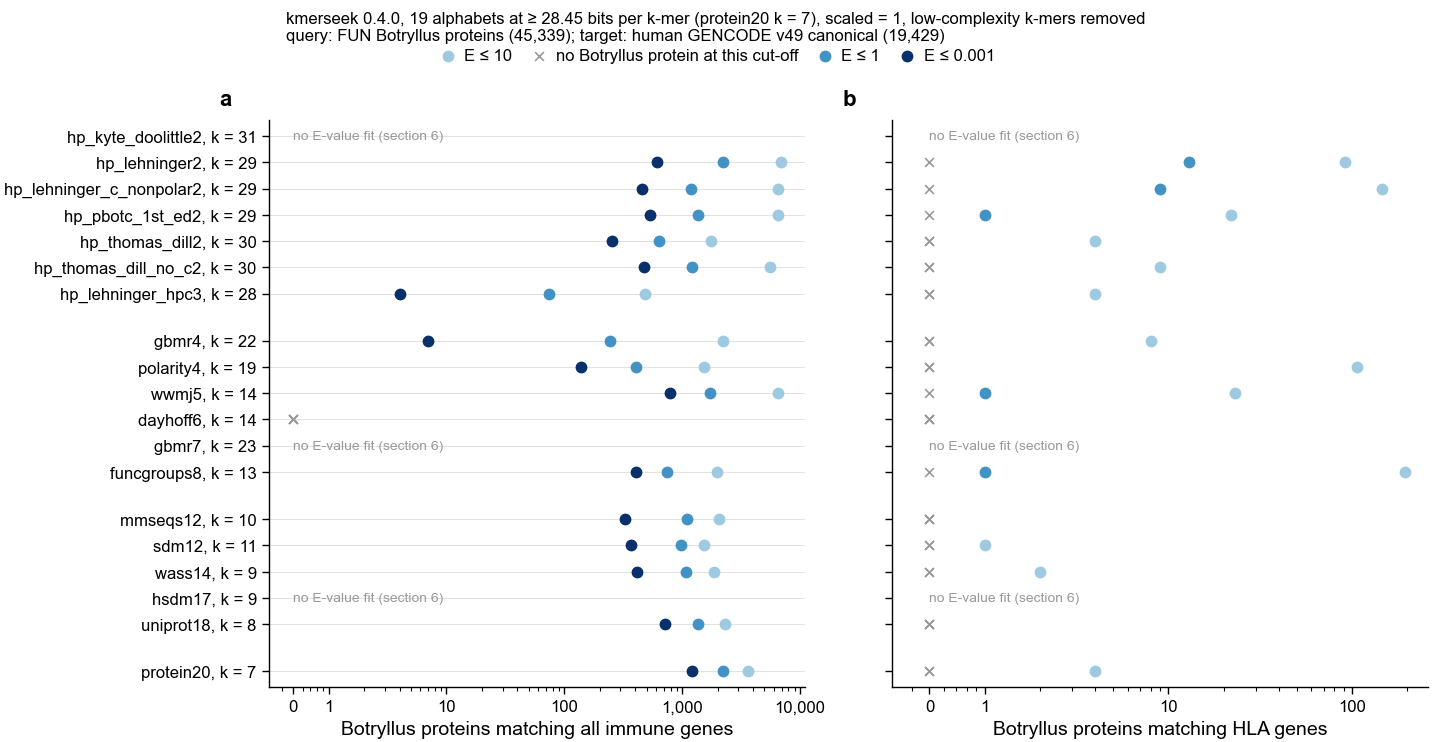

In [5]:
CUTOFF_STYLE = {10: ("#9ecae1", "E ≤ 10"), 1: ("#4292c6", "E ≤ 1"), STRICT_EVALUE: ("#08306b", "E ≤ 0.001")}

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 95, ncols=2, sharey=True)
for ax, gene_set in zip(axs, ["all immune genes", "HLA genes"]):
    for cutoff, (colour, label) in CUTOFF_STYLE.items():
        sub = counts.filter((pl.col("gene_set") == gene_set) & (pl.col("max_evalue") == cutoff))
        ys = [Y_OF[a] for a in sub["alphabet"]]
        n = sub["n_botryllus_proteins"].to_numpy()
        ax.scatter(np.where(n > 0, n, np.nan), ys, color=colour, s=14, zorder=3, label=label)
        ax.scatter(np.where(n == 0, ZERO_X, np.nan), ys, color=pf.GREY, marker="x", s=10, linewidths=0.6,
                   zorder=2, label="no Botryllus protein at this cut-off")
    ax.set_xscale("log")
    ax.set_xlim(ZERO_X / 1.6, None)
    ticks = [t for t in [1, 10, 100, 1_000, 10_000, 100_000] if t <= max(1, counts.filter(pl.col("gene_set") == gene_set)["n_botryllus_proteins"].max()) * 3]
    ax.set_xticks([ZERO_X] + ticks, ["0"] + [f"{t:,}" for t in ticks])
    ax.set_xlabel(f"Botryllus proteins matching {gene_set}")
    mark_no_evalues(ax, ZERO_X)
alphabet_axis(axs[0])
pf.shared_legend(fig, ncol=4, title=f"{TOOL_LINE}\n{QUERY_TARGET_LINE}")
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
pf.save(fig, FIG_DIR / "235b_botryllus_proteins_matching_immune_and_hla_by_evalue_kmerseek_19_alphabets")

How to read it: each row is one alphabet; light to dark blue is loose to strict E-value
cut-off. A grey × at 0 means no Botryllus protein passes that cut-off. Panel b is the question
of this notebook: a dark-blue dot in panel b would be an HLA match at the candidate cut-off.

## 3. The HLA matches in every alphabet with E-values, and which part of the HLA protein they cover

In [6]:
hla = immune.filter("is_hla")
# one HlaParts for every HLA gene matched anywhere in this notebook, extended or not
noext_hla = {a: read_hla_inf(RUN_DIR / "immune" / f"{tag(a)}.noext.immune.evalue_inf.hla.csv.gz") for a in NOEXT_ALPHABETS}
inf_hla_raw = {a: read_hla_inf(RUN_DIR / "immune" / f"{tag(a)}.immune.evalue_inf.hla.csv.gz") for a in ALPHABETS}
lengths = pl.concat([f.select("human_gene", "human_protein_length") for f in
                     [hla, *noext_hla.values(), *inf_hla_raw.values()]]).unique("human_gene")
hla_parts = HlaParts(dict(lengths.iter_rows()))
print(hla_parts.length_check)
hla = hla_parts.add_columns(hla)
assert set(hla["hla_part_matched"]) <= set(PART_COLOUR), set(hla["hla_part_matched"])
hla.sort("region_evalue").write_csv(OUT_DIR / "235_hla_matches_evalue_le_10_kmerseek_botryllus_vs_gencode_19_alphabets.csv")

best_hla = (hla.sort("region_evalue", "query_name", "human_gene").group_by("alphabet", maintain_order=True)
            .agg(pl.len().alias("n_hla_matches"), pl.col("query_name").n_unique().alias("n_botryllus_proteins"),
                 pl.col("region_evalue").first().alias("best_evalue"),
                 pl.col("query_name").first().alias("best_botryllus_protein"),
                 pl.col("human_gene").first().alias("best_hla_gene"),
                 pl.col("hla_part_matched").first().alias("part_matched_by_best")))
best_hla = (arms.filter("has_evalues").select("alphabet", "ksize").join(best_hla, on="alphabet", how="left")
            .with_columns(pl.col("n_hla_matches").fill_null(0), pl.col("n_botryllus_proteins").fill_null(0)))
print(best_hla)
print(f"\nHLA matches at E <= {STRICT_EVALUE} in any alphabet: {hla.filter(pl.col('region_evalue') <= STRICT_EVALUE).height}")
print("\nHLA part covered, all alphabets with E-values together:")
print(hla.group_by("hla_part_matched").agg(pl.len().alias("n_matches")).sort("n_matches", descending=True))
print(hla.filter(pl.col("alphabet") == "funcgroups8").group_by("hla_part_matched")
      .agg(pl.len().alias("n_funcgroups8_matches")).sort("n_funcgroups8_matches", descending=True))

shape: (19, 5)
┌────────────┬─────────┬────────────────┬────────────────┬─────────────┐
│ human_gene ┆ uniprot ┆ uniprot_length ┆ gencode_length ┆ same_length │
│ ---        ┆ ---     ┆ ---            ┆ ---            ┆ ---         │
│ str        ┆ str     ┆ i64            ┆ i64            ┆ bool        │
╞════════════╪═════════╪════════════════╪════════════════╪═════════════╡
│ HLA-A      ┆ P04439  ┆ 365            ┆ 365            ┆ true        │
│ HLA-B      ┆ P01889  ┆ 362            ┆ 362            ┆ true        │
│ HLA-C      ┆ P10321  ┆ 366            ┆ 366            ┆ true        │
│ HLA-DMA    ┆ P28067  ┆ 261            ┆ 261            ┆ true        │
│ HLA-DMB    ┆ P28068  ┆ 263            ┆ 263            ┆ true        │
│ HLA-DOA    ┆ P06340  ┆ 250            ┆ 250            ┆ true        │
│ HLA-DOB    ┆ P13765  ┆ 273            ┆ 273            ┆ true        │
│ HLA-DPA1   ┆ P20036  ┆ 260            ┆ 260            ┆ true        │
│ HLA-DPB1   ┆ P04440  ┆ 258        

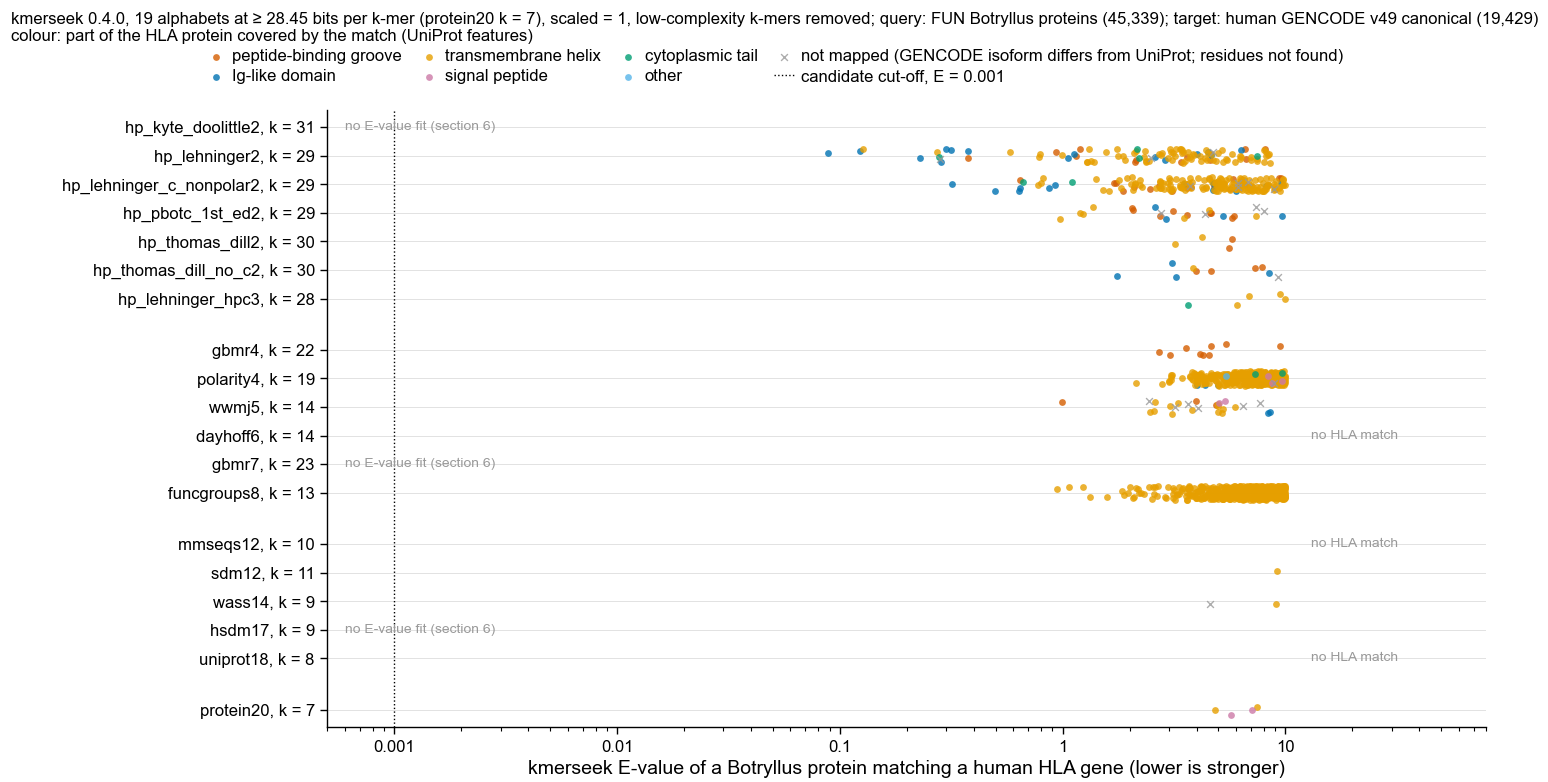

In [7]:
rng = np.random.default_rng(0)
fig, ax = pf.figure(pf.TWO_COLUMN_MM, 100)
for part, colour in PART_COLOUR.items():
    sub = hla.filter(pl.col("hla_part_matched") == part)
    if len(sub) == 0:
        continue
    ys = np.array([Y_OF[a] for a in sub["alphabet"]]) + rng.uniform(-0.25, 0.25, len(sub))
    ax.scatter(sub["region_evalue"], ys, color=colour, s=6, alpha=0.8, marker=PART_MARKER[part],
               linewidths=0 if PART_MARKER[part] == "o" else 0.5, label=part)
for a in ALPHABETS:
    if best_hla.filter(pl.col("alphabet") == a)["n_hla_matches"][0] == 0:
        ax.text(MAX_EVALUE * 1.3, Y_OF[a], "no HLA match", va="center", fontsize=5, color=pf.GREY)
ax.axvline(STRICT_EVALUE, color="black", linewidth=0.5, linestyle=":", label=f"candidate cut-off, E = {STRICT_EVALUE:g}")
ax.set_xscale("log")
left = min(STRICT_EVALUE, hla["region_evalue"].min()) / 2
ax.set_xlim(left, MAX_EVALUE * 8)
mark_no_evalues(ax, left * 1.2)
ticks = [t for t in [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10] if t >= left]
ax.set_xticks(ticks, [f"{t:g}" if t >= 1e-3 else f"{t:.5f}".rstrip("0") for t in ticks])
ax.set_xlabel("kmerseek E-value of a Botryllus protein matching a human HLA gene (lower is stronger)")
alphabet_axis(ax)
pf.shared_legend(fig, ncol=4, title=f"{TOOL_LINE}; {QUERY_TARGET_LINE}\n"
                 "colour: part of the HLA protein covered by the match (UniProt features)")
pf.save(fig, FIG_DIR / "235c_hla_matches_evalue_and_part_kmerseek_botryllus_vs_gencode_19_alphabets")

How to read it: each dot is one Botryllus protein region matched to one HLA protein, in the
row of the alphabet that found it; further left is stronger. A dot left of the dotted line
would meet the candidate rule if its colour is vermillion (groove) or blue (Ig-like).

The best HLA match of each alphabet, in residues (Botryllus first, human second):

In [8]:
best_rows = hla.sort("region_evalue", "query_name", "human_gene").group_by("alphabet", maintain_order=True).first()
for r in best_rows.sort("region_evalue").iter_rows(named=True):
    print(f"{r['alphabet']:<25} {r['query_name']:<24} vs {r['human_gene']:<9} E = {r['region_evalue']:.3g}  "
          f"human residues {r['target_start'] + 1}-{r['target_end']} ({r['hla_part_matched']})")
    print(f"  Botryllus {r['region_subseq'][:100]}")
    print(f"  human     {r['target_subseq'][:100]}\n")

hp_lehninger2             FUN025104_PIK3AP1        vs HLA-E     E = 0.0887  human residues 231-307 (Ig-like domain)
  Botryllus AFKMLLFDSEVLKILKAKDSIFRNSGVLEMQPERVIILLLGDAKNKNFYQEAKLTLCGKFEEVEAYLIAIIRDGALI
  human     PAEITLTWQQDGEGHTQDTELVETRPAGDGTFQKWAAVVVPSGEEQRYTCHVQHEGLPEPVTLRWKPASQPTIPIVG

hp_lehninger_c_nonpolar2  FUN025104_PIK3AP1        vs HLA-E     E = 0.317  human residues 217-307 (Ig-like domain)
  Botryllus TTLADDEICNVNSCAFKMLLFDSEVLKILKAKDSIFRNSGVLEMQPERVIILLLGDAKNKNFYQEAKLTLCGKFEEVEAYLIAIIRDGALI
  human     DHEATLRCWALGFYPAEITLTWQQDGEGHTQDTELVETRPAGDGTFQKWAAVVVPSGEEQRYTCHVQHEGLPEPVTLRWKPASQPTIPIVG

funcgroups8               FUN003998_FUN003998      vs HLA-G     E = 0.945  human residues 310-331 (transmembrane helix)
  Botryllus IIIAIGAGAAVAITIVIVIAVL
  human     GIVAGLVVLAAVVTGAAVAAVL

hp_pbotc_1st_ed2          FUN044276_SLC5A8         vs HLA-C     E = 0.971  human residues 311-342 (transmembrane helix)
  Botryllus VVADYVVFALMLLLSVAIGIYYAHRGRKRNQK
  human     IVAGLAVLVVL

**Every HLA groove or Ig-like match at E ≤ 1**, in residues (Botryllus first, human second).
"Same residue" counts positions where the two sequences carry the same amino acid; kmerseek
matches whole regions without gaps, so position i of one lines up with position i of the other.
Each match gets two chance levels: over all positions with Swiss-Prot residue frequencies, and
over only the positions where both letters fall in one class of the alphabet, where unrelated
sequences already share amino acids more often (`same_residue_vs_chance_in_class`).

In [9]:
groove_ig_le_1 = (hla.filter((pl.col("region_evalue") <= 1) & pl.col("hla_part_matched").is_in(GROOVE_OR_IG))
                  .sort("region_evalue", "alphabet", "query_name")
                  .with_columns(pl.struct("region_subseq", "target_subseq").map_elements(
                      lambda r: sum(a == b for a, b in zip(r["region_subseq"], r["target_subseq"])),
                      return_dtype=pl.Int64).alias("n_same_residue")))
groove_ig_le_1.write_csv(OUT_DIR / "235_hla_groove_or_ig_matches_evalue_le_1_kmerseek_botryllus_vs_gencode_19_alphabets.csv")
print(hla.filter(pl.col("region_evalue") <= 1).group_by("hla_part_matched")
      .agg(pl.len().alias("n_matches"), pl.col("query_name").n_unique().alias("n_botryllus_proteins"),
           pl.col("region_evalue").min().alias("best_evalue")).sort("n_matches", descending=True))
print(f"\nGroove or Ig-like matches at E <= 1: {groove_ig_le_1.height}")
for r in groove_ig_le_1.iter_rows(named=True):
    print(f"\n{r['alphabet']:<25} {r['query_name']:<24} vs {r['human_gene']:<9} E = {r['region_evalue']:.2f}  "
          f"human residues {r['target_start'] + 1}-{r['target_end']} ({r['hla_part_matched']}); "
          f"same residue at {r['n_same_residue']} of {len(r['region_subseq'])} positions")
    chance = same_residue_vs_chance(r["region_subseq"], r["target_subseq"])
    print(f"  unrelated sequences with Swiss-Prot residue frequencies: {chance['n_expected']:.1f} expected, "
          f"chance of {chance['n_same']} or more = {chance['p_at_least']:.2g}")
    in_class = same_residue_vs_chance_in_class(r["region_subseq"], r["target_subseq"], r["alphabet"])
    print(f"  counting only the {in_class['n_positions']} positions where both letters are in one class of "
          f"{r['alphabet']}: {in_class['n_same']} same, {in_class['n_expected']:.1f} expected, "
          f"chance {in_class['p_at_least']:.2g}")
    print(f"  Botryllus {r['region_subseq'][:100]}")
    print(f"            {match_line(r['region_subseq'], r['target_subseq'])[:100]}")
    print(f"  human     {r['target_subseq'][:100]}")

shape: (5, 4)
┌───────────────────────────────────────────────────────────────┬───────────┬──────────────────────┬─────────────┐
│ hla_part_matched                                              ┆ n_matches ┆ n_botryllus_proteins ┆ best_evalue │
│ ---                                                           ┆ ---       ┆ ---                  ┆ ---         │
│ str                                                           ┆ u32       ┆ u32                  ┆ f64         │
╞═══════════════════════════════════════════════════════════════╪═══════════╪══════════════════════╪═════════════╡
│ Ig-like domain                                                ┆ 13        ┆ 5                    ┆ 0.088714    │
│ transmembrane helix                                           ┆ 11        ┆ 8                    ┆ 0.126849    │
│ peptide-binding groove                                        ┆ 4         ┆ 4                    ┆ 0.375293    │
│ cytoplasmic tail                                              ┆ 

**Matches found by several alphabets.** For each Botryllus protein and HLA gene, the number
of alphabets with a match at E ≤ 1, and the best E-value among them:

In [10]:
shared = (hla.filter(pl.col("region_evalue") <= 1)
          .group_by("query_name", "human_gene")
          .agg(pl.col("alphabet").n_unique().alias("n_alphabets"), pl.col("region_evalue").min().alias("best_evalue"),
               pl.col("alphabet").unique().sort().str.join(", ").alias("alphabets"),
               pl.col("hla_part_matched").mode().sort().first().alias("most_common_part"))
          .sort("n_alphabets", "best_evalue", "query_name", "human_gene", descending=[True, False, False, False]))
shared.write_csv(OUT_DIR / "235_hla_matches_shared_by_alphabets_evalue_le_1.csv")
print(f"{shared.height} Botryllus protein and HLA gene pairs at E <= 1")
print(shared.head(20))

23 Botryllus protein and HLA gene pairs at E <= 1
shape: (20, 6)
┌─────────────────────┬────────────┬─────────────┬─────────────┬─────────────────────────────────────────┬───────────────────────────────────────────────────────────────┐
│ query_name          ┆ human_gene ┆ n_alphabets ┆ best_evalue ┆ alphabets                               ┆ most_common_part                                              │
│ ---                 ┆ ---        ┆ ---         ┆ ---         ┆ ---                                     ┆ ---                                                           │
│ str                 ┆ str        ┆ u32         ┆ f64         ┆ str                                     ┆ str                                                           │
╞═════════════════════╪════════════╪═════════════╪═════════════╪═════════════════════════════════════════╪═══════════════════════════════════════════════════════════════╡
│ FUN025104_PIK3AP1   ┆ HLA-E      ┆ 2           ┆ 0.088714    ┆ hp_lehninger2, 

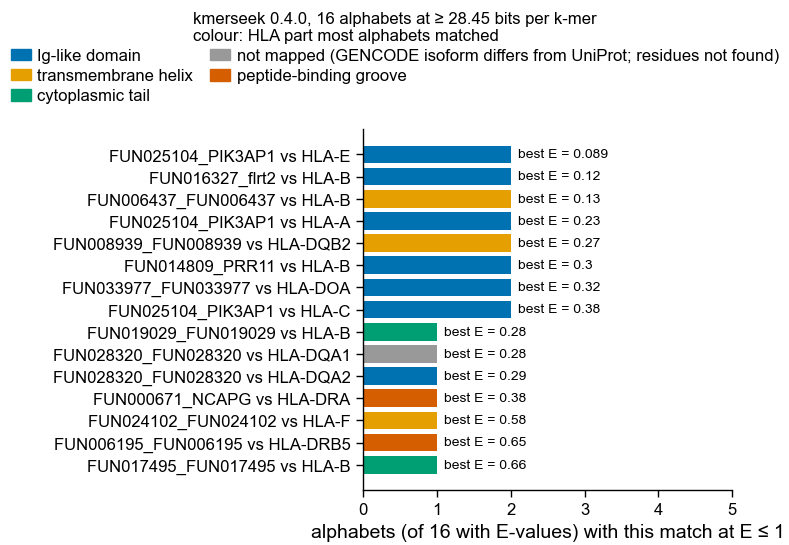

In [11]:
show = shared.head(15)
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 70)
labels = [f"{q} vs {g}" for q, g in zip(show["query_name"], show["human_gene"])]
ax.barh(range(len(show)), show["n_alphabets"], color=[PART_COLOUR[p] for p in show["most_common_part"]])
for i, (n, e) in enumerate(zip(show["n_alphabets"], show["best_evalue"])):
    ax.text(n + 0.1, i, f"best E = {e:.2g}", va="center", fontsize=5)
ax.set_yticks(range(len(show)), labels)
ax.invert_yaxis()
ax.set_xlim(0, max(show["n_alphabets"].max() + 3, 4))
ax.set_xlabel(f"alphabets (of {len(ALPHABETS)} with E-values) with this match at E ≤ 1")
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=PART_COLOUR[p], label=p) for p in dict.fromkeys(show["most_common_part"])],
           loc="outside upper center", ncol=2,
           title=f"kmerseek 0.4.0, {len(ALPHABETS)} alphabets at ≥ 28.45 bits per k-mer\ncolour: HLA part most alphabets matched")
pf.save(fig, FIG_DIR / "235d_hla_matches_shared_by_alphabets_kmerseek_botryllus_vs_gencode")

## 4. The strongest matches to well-known immune families, per alphabet with E-values

Genes from the hand-picked family list of notebook 232 (HLA, antigen processing, Toll-like
and NOD-like receptors, complement, cytokines and receptors, interferons, TNF family,
NF-κB, IRF, TRAF, JAK/STAT, lymphocyte kinases, CD antigens, KIR/LILR, Fc receptors,
immunoglobulin and T-cell receptor genes, RAG, AIRE). Shown: every such gene with E ≤ 0.001
in at least one alphabet.

In [12]:
known = immune.filter(pl.col("human_gene").str.contains(KNOWN_IMMUNE_FAMILY_PATTERN))
best_known = known.group_by("human_gene", "alphabet").agg(pl.col("region_evalue").min().alias("best_evalue"))
strong_genes = (best_known.filter(pl.col("best_evalue") <= STRICT_EVALUE).group_by("human_gene")
                .agg(pl.col("best_evalue").min().alias("best_any"), pl.len().alias("n_alphabets_strict"))
                .sort("best_any", "human_gene"))
table = (best_known.filter(pl.col("human_gene").is_in(strong_genes["human_gene"].implode()))
         .pivot(on="alphabet", index="human_gene", values="best_evalue")
         .join(strong_genes, on="human_gene").sort("best_any", "human_gene"))
table = table.select("human_gene", "best_any", "n_alphabets_strict", *[a for a in ALPHABETS if a in table.columns])
table.write_csv(OUT_DIR / "235_best_evalue_known_immune_genes_by_alphabet.csv")
print(f"{strong_genes.height} well-known immune genes with E <= {STRICT_EVALUE} in at least one alphabet")
print(table.select("human_gene", "best_any", "n_alphabets_strict"))

23 well-known immune genes with E <= 0.001 in at least one alphabet
shape: (23, 3)
┌────────────┬────────────┬────────────────────┐
│ human_gene ┆ best_any   ┆ n_alphabets_strict │
│ ---        ┆ ---        ┆ ---                │
│ str        ┆ f64        ┆ u32                │
╞════════════╪════════════╪════════════════════╡
│ PSMB8      ┆ 3.4998e-24 ┆ 12                 │
│ TRAF3      ┆ 1.6918e-22 ┆ 12                 │
│ PSMB10     ┆ 5.6480e-17 ┆ 6                  │
│ LCK        ┆ 1.0718e-16 ┆ 12                 │
│ BTK        ┆ 8.2071e-13 ┆ 5                  │
│ NFKB1      ┆ 1.4798e-12 ┆ 6                  │
│ IRF4       ┆ 7.3223e-11 ┆ 4                  │
│ TRAF2      ┆ 1.5128e-9  ┆ 4                  │
│ PSMB9      ┆ 5.3473e-9  ┆ 2                  │
│ ZAP70      ┆ 3.4317e-8  ┆ 6                  │
│ TAP2       ┆ 3.2468e-7  ┆ 5                  │
│ SYK        ┆ 3.7097e-7  ┆ 8                  │
│ RELA       ┆ 0.000001   ┆ 1                  │
│ JAK3       ┆ 0.000001   ┆ 2      

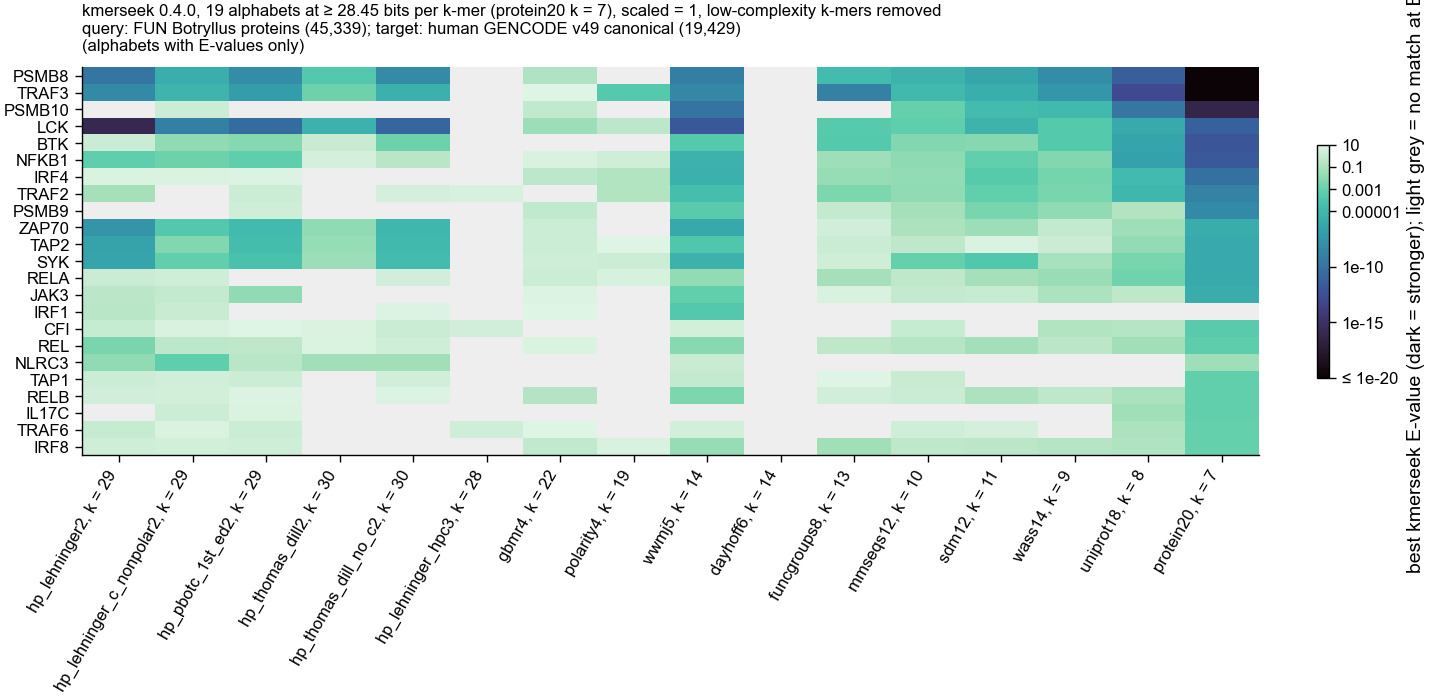

In [13]:
genes = table["human_gene"].to_list()
grid = np.full((len(genes), len(ALPHABETS)), np.nan)
for i, g in enumerate(genes):
    row = table.filter(pl.col("human_gene") == g).row(0, named=True)
    for j, a in enumerate(ALPHABETS):
        if a in row and row[a] is not None:
            grid[i, j] = np.log10(max(row[a], 1e-50))
cmap = plt.get_cmap("mako").copy()
cmap.set_bad("#eeeeee")
fig, ax = pf.figure(pf.TWO_COLUMN_MM, min(165, max(40, 30 + 2.6 * len(genes))))
FLOOR = -20  # stronger than 1e-20 all get the darkest colour, so the weaker squares stay readable
im = ax.imshow(np.ma.masked_invalid(np.clip(grid, FLOOR, None)), aspect="auto", cmap=cmap, vmin=FLOOR, vmax=1)
ax.set_xticks(range(len(ALPHABETS)), [LABEL_OF[a] for a in ALPHABETS], rotation=60, ha="right")
ax.set_yticks(range(len(genes)), genes)
cbar = fig.colorbar(im, ax=ax, shrink=0.6)
cbar.set_ticks([-20, -15, -10, -5, -3, -1, 1],
               labels=["≤ 1e-20", "1e-15", "1e-10", "0.00001", "0.001", "0.1", "10"])
cbar.set_label("best kmerseek E-value (dark = stronger); light grey = no match at E ≤ 10")
ax.set_title(f"{TOOL_LINE}\n{QUERY_TARGET_LINE}\n(alphabets with E-values only)", fontsize=6, loc="left")
pf.save(fig, FIG_DIR / "235e_best_evalue_known_immune_genes_by_alphabet_kmerseek_botryllus")

## 5. Immune matches kmerseek did not extend (E = inf), alphabets with E-values

Summarised on Sherlock per alphabet: matches, Botryllus proteins and human immune genes, and
every unextended match to an HLA gene. With no E-value, the only measure of strength is
`region_tail_probability`, the chance of this many shared k-mers in the region. kmerseek
0.4.0 writes it uncorrected, and each alphabet makes 45,339 × 19,429 ≈ 0.88 billion
protein-pair comparisons, so a match counts here only below 0.05 / 0.88 billion ≈ 5.7e-11
(Bonferroni).

In [14]:
inf_rows, inf_hla = [], []
for a in ALPHABETS:
    t = pl.read_csv(RUN_DIR / "immune" / f"{tag(a)}.immune.evalue_inf.totals.tsv", separator="\t").row(0, named=True)
    h = inf_hla_raw[a]
    inf_rows.append({"alphabet": a, **t, "n_hla_matches": len(h),
                     "n_hla_botryllus_proteins": h["query_name"].n_unique() if len(h) else 0})
    if len(h):
        inf_hla.append(h.with_columns(pl.lit(a).alias("alphabet")))
inf_totals = pl.DataFrame(inf_rows)
inf_totals.write_csv(OUT_DIR / "235_immune_matches_not_extended_totals_alphabets_with_evalues.csv")
print(inf_totals)
inf_hla = hla_parts.add_columns(pl.concat(inf_hla))
(inf_hla.filter(pl.col("region_tail_probability") < P_THRESHOLD).sort("region_tail_probability")
 .write_csv(OUT_DIR / "235_hla_matches_not_extended_below_corrected_p_alphabets_with_evalues.csv"))
inf_hla_counts = (inf_hla.group_by("alphabet")
                  .agg(pl.len().alias("n_hla_matches"),
                       pl.col("query_name").n_unique().alias("n_botryllus_proteins"),
                       (pl.col("region_tail_probability") < P_THRESHOLD).sum().alias("n_below_corrected_0.05"),
                       (pl.col("region_tail_probability") == 0).sum().alias("n_p_exactly_0"))
                  .sort("n_hla_matches", "alphabet", descending=[True, False]))
print(f"\nUnextended HLA matches per alphabet; corrected threshold 0.05 / {N_PAIRS:,} pairs = {P_THRESHOLD:.2g}")
print(inf_hla_counts)
print(f"All alphabets with E-values: {inf_hla_counts['n_hla_matches'].sum():,} unextended HLA matches, "
      f"{inf_hla_counts['n_below_corrected_0.05'].sum():,} below the corrected threshold, "
      f"{inf_hla_counts['n_p_exactly_0'].sum():,} with p = 0")

# Do the groove and Ig-like matches below the threshold share more amino acids than chance?
# A k-mer match puts both residues of each position in the same letter class, so the chance
# level is computed within the class (hla_utils.same_residue_vs_chance_in_class).
groove_ig_inf = inf_hla.filter((pl.col("region_tail_probability") < P_THRESHOLD)
                               & pl.col("hla_part_matched").is_in(GROOVE_OR_IG))
tests = pl.DataFrame([{"alphabet": r["alphabet"], "query_name": r["query_name"], "human_gene": r["human_gene"],
                       "hla_part_matched": r["hla_part_matched"],
                       **same_residue_vs_chance_in_class(r["region_subseq"], r["target_subseq"], r["alphabet"])}
                      for r in groove_ig_inf.iter_rows(named=True)])
tests = tests.sort("p_at_least", "alphabet", "query_name", "human_gene")
print(f"\nGroove or Ig-like matches below the threshold: {tests.height:,}. With the same letter class at a "
      f"position, {(tests['p_at_least'] < 0.001).sum()} share more amino acids than unrelated sequences at chance "
      f"below 0.001 (about {tests.height * 0.001:.1f} expected by chance alone); smallest chance "
      f"{tests['p_at_least'].min():.2g}. The 5 with the smallest chance:")
print(tests.head(5).with_columns(pl.col("n_expected").round(1), pl.col("p_at_least").round(4)))

shape: (16, 6)
┌──────────────────────────┬───────────┬──────────────────────┬───────────────┬───────────────┬──────────────────────────┐
│ alphabet                 ┆ n_matches ┆ n_botryllus_proteins ┆ n_human_genes ┆ n_hla_matches ┆ n_hla_botryllus_proteins │
│ ---                      ┆ ---       ┆ ---                  ┆ ---           ┆ ---           ┆ ---                      │
│ str                      ┆ i64       ┆ i64                  ┆ i64           ┆ i64           ┆ i64                      │
╞══════════════════════════╪═══════════╪══════════════════════╪═══════════════╪═══════════════╪══════════════════════════╡
│ hp_lehninger2            ┆ 4         ┆ 3                    ┆ 2             ┆ 0             ┆ 0                        │
│ hp_lehninger_c_nonpolar2 ┆ 5         ┆ 5                    ┆ 4             ┆ 0             ┆ 0                        │
│ hp_pbotc_1st_ed2         ┆ 129       ┆ 24                   ┆ 10            ┆ 0             ┆ 0                        │
│

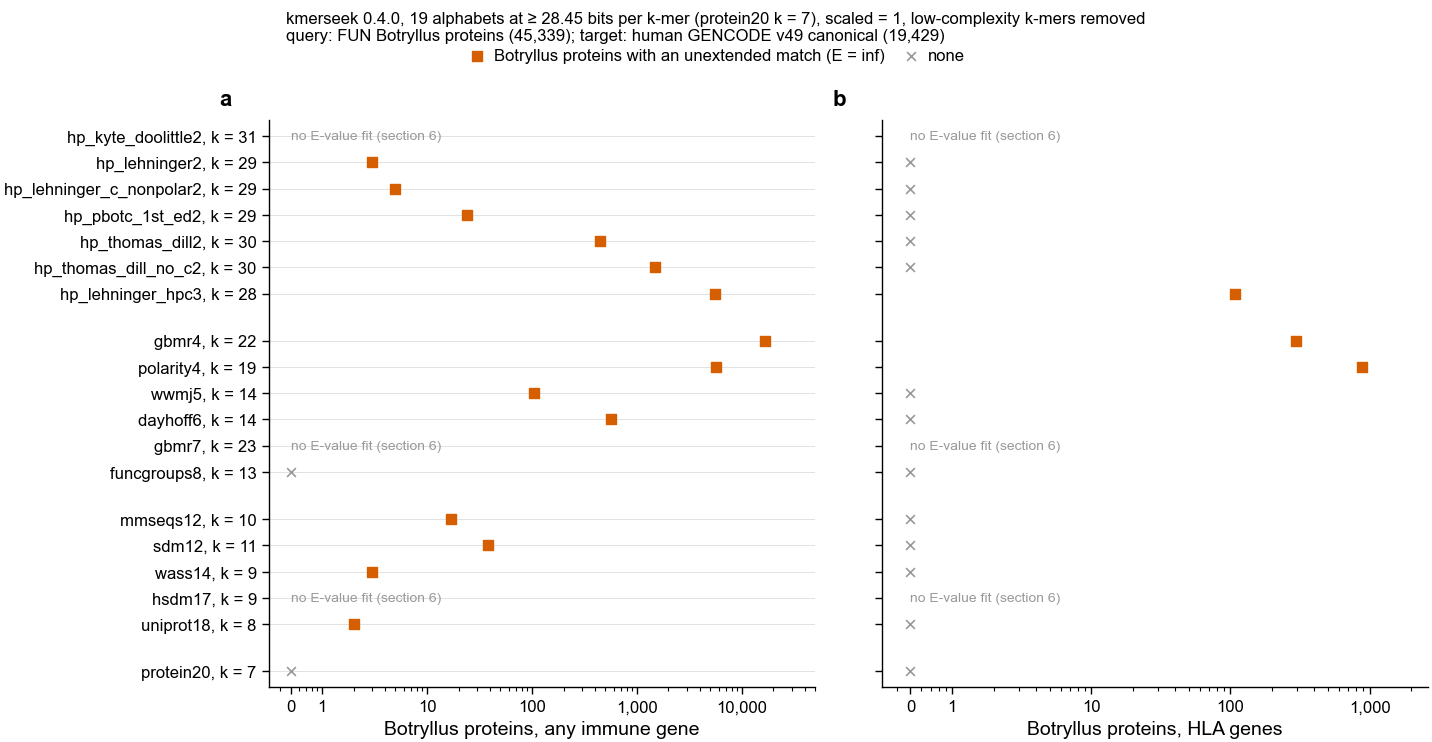

In [15]:
fig, (ax_a, ax_b) = pf.figure(pf.TWO_COLUMN_MM, 95, ncols=2, sharey=True)
for ax, col in [(ax_a, "n_botryllus_proteins"), (ax_b, "n_hla_botryllus_proteins")]:
    n = inf_totals[col].to_numpy()
    ys = [Y_OF[a] for a in inf_totals["alphabet"]]
    ax.scatter(np.where(n > 0, n, np.nan), ys, color=pf.OKABE_ITO["vermillion"], marker="s", s=12, zorder=3,
               label="Botryllus proteins with an unextended match (E = inf)")
    ax.scatter(np.where(n == 0, ZERO_X, np.nan), ys, color=pf.GREY, marker="x", s=10, linewidths=0.6,
               label="none")
    ax.set_xscale("log")
    ax.set_xlim(ZERO_X / 1.6, max(n.max(), 1) * 3)
    ticks = [t for t in [1, 10, 100, 1_000, 10_000, 100_000] if t <= max(n.max(), 1) * 3]
    ax.set_xticks([ZERO_X] + ticks, ["0"] + [f"{t:,}" for t in ticks])
    mark_no_evalues(ax, ZERO_X)
ax_a.set_xlabel("Botryllus proteins, any immune gene")
ax_b.set_xlabel("Botryllus proteins, HLA genes")
alphabet_axis(ax_a)
pf.shared_legend(fig, ncol=2, title=f"{TOOL_LINE}\n{QUERY_TARGET_LINE}")
for ax, letter in zip((ax_a, ax_b), "ab"):
    pf.panel_label(ax, letter)
pf.save(fig, FIG_DIR / "235f_immune_matches_not_extended_kmerseek_botryllus_vs_gencode_alphabets_with_evalues")

## 6. Alphabets without E-values: the region p-value rule

For the alphabets whose E-value fit failed, every match is unextended and the second rule of
the introduction applies. A match must pass all three steps: (1) region p-value below
0.05 / 880,891,431; (2) it covers the HLA groove or Ig-like domain; (3) its two stretches
share more amino acids than unrelated sequences would, given that each position already
carries letters of one class, at a chance below 0.05 divided by the number of matches
passing steps 1 and 2 in that alphabet.

In [16]:
funnel, step2_frames = [], []
for a in NOEXT_ALPHABETS:
    t = pl.read_csv(RUN_DIR / "immune" / f"{tag(a)}.noext.immune.evalue_inf.totals.tsv", separator="\t").row(0, named=True)
    h = hla_parts.add_columns(noext_hla[a]).with_columns(pl.lit(a).alias("alphabet"))
    step1 = h.filter(pl.col("region_tail_probability") < P_THRESHOLD)
    step2 = step1.filter(pl.col("hla_part_matched").is_in(GROOVE_OR_IG))
    cut3 = 0.05 / max(step2.height, 1)
    step2 = step2.with_columns(pl.struct("region_subseq", "target_subseq").map_elements(
        lambda r: same_residue_vs_chance_in_class(r["region_subseq"], r["target_subseq"], a),
        return_dtype=pl.Struct({"n_positions": pl.Int64, "n_same": pl.Int64, "n_expected": pl.Float64,
                                "p_at_least": pl.Float64})).alias("same_class")).unnest("same_class")
    step2 = step2.with_columns(pl.lit(cut3).alias("step3_cutoff"), (pl.col("p_at_least") < cut3).alias("passes_step3"))
    step2_frames.append(step2)
    funnel.append({"alphabet": a, "ksize": K_OF[a], "n_immune_matches": t["n_matches"],
                   "n_immune_botryllus_proteins": t["n_botryllus_proteins"],
                   "n_hla_matches": h.height, "n_hla_botryllus_proteins": h["query_name"].n_unique(),
                   "n_step1_p_below_threshold": step1.height, "n_step2_groove_or_ig": step2.height,
                   "step3_cutoff": cut3, "n_step3_more_same_residues_than_chance": step2["passes_step3"].sum(),
                   "n_candidate_botryllus_proteins": step2.filter("passes_step3")["query_name"].n_unique()})
funnel = pl.DataFrame(funnel)
funnel.write_csv(OUT_DIR / "235_noext_alphabets_p_value_rule_steps.csv")
step2_all = pl.concat(step2_frames).sort("p_at_least", "alphabet", "query_name", "human_gene")
step2_all.drop("region_subseq", "target_subseq").write_csv(OUT_DIR / "235_noext_alphabets_groove_or_ig_matches_below_p.csv")
print(funnel)
print(f"\nAll {len(NOEXT_ALPHABETS)} alphabets without E-values: {funnel['n_hla_matches'].sum()} unextended HLA matches, "
      f"{funnel['n_step1_p_below_threshold'].sum()} pass step 1, {funnel['n_step2_groove_or_ig'].sum()} pass steps 1 and 2, "
      f"{funnel['n_step3_more_same_residues_than_chance'].sum()} pass all three; smallest step-3 chance "
      f"{step2_all['p_at_least'].min():.2g}")
print("\nHLA part of the matches below the p-value threshold, per alphabet:")
print(pl.concat([hla_parts.add_columns(noext_hla[a]).with_columns(pl.lit(a).alias("alphabet")) for a in NOEXT_ALPHABETS])
      .filter(pl.col("region_tail_probability") < P_THRESHOLD)
      .group_by("alphabet", "hla_part_matched").agg(pl.len().alias("n_matches"))
      .sort("alphabet", "n_matches", descending=[False, True]))

shape: (3, 11)
┌────────────────────┬───────┬──────────────────┬───────────────────────┬───────────────┬───────────────────────┬──────────────────────┬──────────────────────┬──────────────┬──────────────────────┬──────────────────────┐
│ alphabet           ┆ ksize ┆ n_immune_matches ┆ n_immune_botryllus_pr ┆ n_hla_matches ┆ n_hla_botryllus_prote ┆ n_step1_p_below_thre ┆ n_step2_groove_or_ig ┆ step3_cutoff ┆ n_step3_more_same_re ┆ n_candidate_botryllu │
│ ---                ┆ ---   ┆ ---              ┆ oteins                ┆ ---           ┆ ins                   ┆ shold                ┆ ---                  ┆ ---          ┆ sidues_than_chance   ┆ s_proteins           │
│ str                ┆ i64   ┆ i64              ┆ ---                   ┆ i64           ┆ ---                   ┆ ---                  ┆ i64                  ┆ f64          ┆ ---                  ┆ ---                  │
│                    ┆       ┆                  ┆ i64                   ┆               ┆ i64        

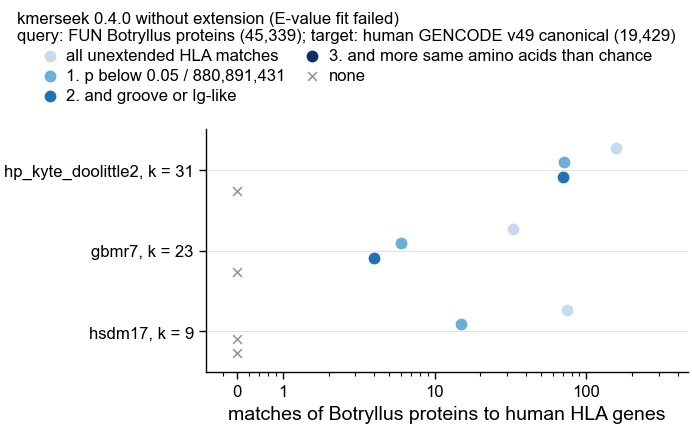

In [17]:
STEP_STYLE = [("n_hla_matches", "#c6dbef", "all unextended HLA matches"),
              ("n_step1_p_below_threshold", "#6baed6", "1. p below 0.05 / 880,891,431"),
              ("n_step2_groove_or_ig", "#2171b5", "2. and groove or Ig-like"),
              ("n_step3_more_same_residues_than_chance", "#08306b", "3. and more same amino acids than chance")]
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 55)
for i, (col, colour, label) in enumerate(STEP_STYLE):
    n = funnel[col].to_numpy()
    ys = np.arange(funnel.height) + (i - 1.5) * 0.18
    ax.scatter(np.where(n > 0, n, np.nan), ys, color=colour, s=14, zorder=3, label=label)
    ax.scatter(np.where(n == 0, ZERO_X, np.nan), ys, color=pf.GREY, marker="x", s=10, linewidths=0.6, zorder=2)
ax.scatter([], [], color=pf.GREY, marker="x", s=10, linewidths=0.6, label="none")
ax.set_yticks(range(funnel.height), [LABEL_OF[a] for a in funnel["alphabet"]])
for yy in range(funnel.height):
    ax.axhline(yy, color="#dddddd", linewidth=0.3, zorder=0)
ax.set_ylim(funnel.height - 0.5, -0.5)
ax.set_xscale("log")
top = max(funnel["n_hla_matches"].max(), 1) * 3
ticks = [t for t in [1, 10, 100, 1_000] if t <= top]
ax.set_xlim(ZERO_X / 1.6, top)
ax.set_xticks([ZERO_X] + ticks, ["0"] + [f"{t:,}" for t in ticks])
ax.set_xlabel("matches of Botryllus proteins to human HLA genes")
fig.legend(loc="outside upper center", ncol=2,
           title="kmerseek 0.4.0 without extension (E-value fit failed)\n" + QUERY_TARGET_LINE)
pf.save(fig, FIG_DIR / "235g_noext_alphabets_hla_matches_through_p_value_rule_kmerseek_botryllus")

How to read it: each row is one alphabet searched without extension. Light to dark blue are
the matches left after each step of the rule; a dark-blue dot would be an MHC-like candidate.
The groove or Ig-like matches that pass steps 1 and 2, in residues, with the same-class test:

In [18]:
for r in step2_all.iter_rows(named=True):
    print(f"{r['alphabet']:<20} {r['query_name']:<24} vs {r['human_gene']:<9} p = {r['region_tail_probability']:.2g}, "
          f"human residues {r['target_start'] + 1}-{r['target_end']} ({r['hla_part_matched']})")
    print(f"  same amino acid at {r['n_same']} of {r['n_positions']} same-class positions, {r['n_expected']:.1f} expected; "
          f"chance {r['p_at_least']:.2g} (step 3 needs below {r['step3_cutoff']:.2g})")
    print(f"  Botryllus {r['region_subseq'][:100]}")
    print(f"            {match_line(r['region_subseq'], r['target_subseq'])[:100]}")
    print(f"  human     {r['target_subseq'][:100]}\n")

hp_kyte_doolittle2   FUN002335_SMC3           vs HLA-B     p = 0, human residues 87-121 (peptide-binding groove)
  same amino acid at 7 of 35 same-class positions, 4.1 expected; chance 0.099 (step 3 needs below 0.00071)
  Botryllus EYTIYNLELSETKSKLDNLSNRRENSSLQTRHLRQ
               ||          | ||      |      |  
  human     NTQIYKAQAQTDRESLRNLRGYYNQSEAGSHTLQS

hp_kyte_doolittle2   FUN024128_ITLN1          vs HLA-F     p = 1.5e-12, human residues 65-97 (peptide-binding groove)
  same amino acid at 6 of 33 same-class positions, 3.7 expected; chance 0.15 (step 3 needs below 0.00071)
  Botryllus QVPPGKRGARGEKGDRGSPDRTGVSAEIDYDRV
               |       |             |    |||
  human     RMEPREPWVEQEGPQYWEWTTGYAKANAQTDRV

hp_kyte_doolittle2   FUN016583_HSPG2          vs HLA-C     p = 3.3e-16, human residues 108-141 (peptide-binding groove)
  same amino acid at 5 of 34 same-class positions, 3.0 expected; chance 0.17 (step 3 needs below 0.00071)
  Botryllus DGYYRSSNSPHLGTCSKCSCNGHGTVCDKDTGKC

## 7. Does kmerseek's best human match agree with the gene name funannotate gave?

17,455 FUN proteins carry a gene name from funannotate (`FUN000002_NLRC5`), assigned by its
own similarity search. For each named Botryllus protein with an immune match at E ≤ 0.001,
take its best match in each alphabet with E-values and ask whether the human gene has the
same name. This checks the run: alphabets that find real homologues should agree with
funannotate often. Names differ for paralogues, so agreement well below 100% is expected.
Only matches to human immune genes were kept on Sherlock, so "best match" here means the
best immune-gene match.

In [19]:
best_per_protein = (immune.filter(pl.col("fun_name").is_not_null() & (pl.col("region_evalue") <= STRICT_EVALUE))
                    .sort("region_evalue", "human_gene").group_by("alphabet", "query_name", maintain_order=True).first()
                    .with_columns((pl.col("fun_name").str.to_uppercase() == pl.col("human_gene")).alias("same_name")))
agree = (best_per_protein.group_by("alphabet")
         .agg(pl.len().alias("n_named_botryllus_proteins"), pl.col("same_name").sum().alias("n_same_name"))
         .with_columns((pl.col("n_same_name") / pl.col("n_named_botryllus_proteins")).alias("fraction_same_name")))
agree = arms.filter("has_evalues").select("alphabet", "ksize").join(agree, on="alphabet", how="left").fill_null(0)
agree.write_csv(OUT_DIR / "235_fun_name_agrees_with_best_human_immune_match_evalue_le_0.001.csv")
print(agree)
big = agree.filter(pl.col("n_named_botryllus_proteins") >= 100)
print(f"\nAlphabets with at least 100 named proteins: {big.height}; agreement from "
      f"{big['fraction_same_name'].min():.0%} to {big['fraction_same_name'].max():.0%}")

shape: (16, 5)
┌──────────────────────────┬───────┬────────────────────────────┬─────────────┬────────────────────┐
│ alphabet                 ┆ ksize ┆ n_named_botryllus_proteins ┆ n_same_name ┆ fraction_same_name │
│ ---                      ┆ ---   ┆ ---                        ┆ ---         ┆ ---                │
│ str                      ┆ i64   ┆ u32                        ┆ u32         ┆ f64                │
╞══════════════════════════╪═══════╪════════════════════════════╪═════════════╪════════════════════╡
│ hp_lehninger2            ┆ 29    ┆ 574                        ┆ 236         ┆ 0.41115            │
│ hp_lehninger_c_nonpolar2 ┆ 29    ┆ 433                        ┆ 207         ┆ 0.47806            │
│ hp_pbotc_1st_ed2         ┆ 29    ┆ 498                        ┆ 231         ┆ 0.463855           │
│ hp_thomas_dill2          ┆ 30    ┆ 245                        ┆ 133         ┆ 0.542857           │
│ hp_thomas_dill_no_c2     ┆ 30    ┆ 438                        ┆ 221       

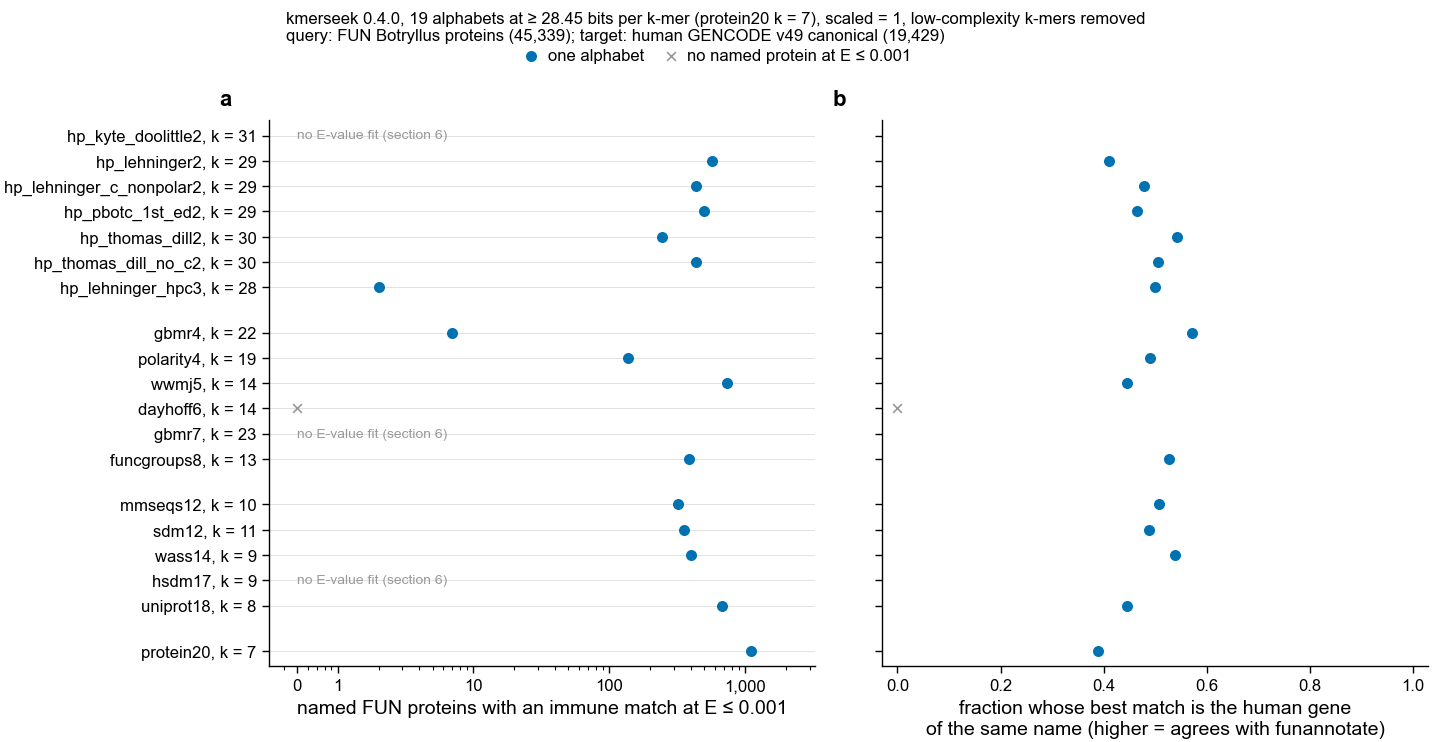

In [20]:
fig, (ax_a, ax_b) = pf.figure(pf.TWO_COLUMN_MM, 95, ncols=2, sharey=True)
for a in ALPHABETS:
    r = agree.filter(pl.col("alphabet") == a).row(0, named=True)
    n = r["n_named_botryllus_proteins"]
    if n > 0:
        ax_a.scatter(n, Y_OF[a], color=pf.OKABE_ITO["blue"], s=12, zorder=3)
        ax_b.scatter(r["fraction_same_name"], Y_OF[a], color=pf.OKABE_ITO["blue"], s=12, zorder=3)
    else:
        ax_a.scatter(ZERO_X, Y_OF[a], color=pf.GREY, marker="x", s=10, linewidths=0.6, zorder=2)
        ax_b.scatter(0, Y_OF[a], color=pf.GREY, marker="x", s=10, linewidths=0.6, zorder=2)
ax_a.scatter([], [], color=pf.OKABE_ITO["blue"], s=12, label="one alphabet")
ax_a.scatter([], [], color=pf.GREY, marker="x", s=10, linewidths=0.6, label="no named protein at E ≤ 0.001")
ax_a.set_xscale("log")
top = max(agree["n_named_botryllus_proteins"].max(), 1) * 3
ticks = [t for t in [1, 10, 100, 1_000, 10_000] if t <= top]
ax_a.set_xlim(ZERO_X / 1.6, top)
ax_a.set_xticks([ZERO_X] + ticks, ["0"] + [f"{t:,}" for t in ticks])
ax_a.set_xlabel("named FUN proteins with an immune match at E ≤ 0.001")
mark_no_evalues(ax_a, ZERO_X)
ax_b.set_xlim(-0.03, 1.03)
ax_b.set_xlabel("fraction whose best match is the human gene\nof the same name (higher = agrees with funannotate)")
alphabet_axis(ax_a)
pf.shared_legend(fig, ncol=2, title=f"{TOOL_LINE}\n{QUERY_TARGET_LINE}")
for ax, letter in zip((ax_a, ax_b), "ab"):
    pf.panel_label(ax, letter)
pf.save(fig, FIG_DIR / "235h_fun_name_agrees_with_best_human_immune_match_kmerseek_alphabets")

## 8. This run (protein20 k = 7 bits) against notebook 234 (24 bits), per alphabet

Same query, target and alphabets; only k changes. Notebook 234's counts are read from its
committed table. The k of each alphabet in both runs, and the Botryllus proteins matching
immune and HLA genes at each E-value cut-off. Alphabets without E-values here have no row.

In [21]:
old_arms = pl.read_csv("233_arms.tsv", separator="\t").select("alphabet", pl.col("ksize").alias("k_234"),
                                                               pl.col("bits_per_kmer").alias("bits_234"))
print(old_arms.join(arms.select("alphabet", pl.col("ksize").alias("k_235"), pl.col("bits_per_kmer").alias("bits_235"),
                                "has_evalues"), on="alphabet"))
old_counts = pl.read_csv("234_outputs/234_immune_hla_counts_by_evalue_kmerseek_botryllus_vs_gencode_19_alphabets.csv")
both = (old_counts.rename({"n_botryllus_proteins": "proteins_234", "n_matches": "matches_234"})
        .select("alphabet", "gene_set", "max_evalue", "proteins_234", "matches_234")
        .join(counts.rename({"n_botryllus_proteins": "proteins_235", "n_matches": "matches_235"})
              .select("alphabet", "gene_set", "max_evalue", "proteins_235", "matches_235"),
              on=["alphabet", "gene_set", "max_evalue"], how="inner"))
both.write_csv(OUT_DIR / "235_immune_hla_counts_24_bits_vs_protein20_k7_bits_by_evalue.csv")
print(both.filter(pl.col("max_evalue") == STRICT_EVALUE).sort("gene_set", "alphabet"))
print("\nHLA genes at E <= 1:")
print(both.filter((pl.col("max_evalue") == 1) & (pl.col("gene_set") == "HLA genes")).sort("alphabet"))
print(f"\nSummed over the {both['alphabet'].n_unique()} alphabets with E-values in both runs "
      "(a protein found by several alphabets counts once for each):")
print(both.group_by("gene_set", "max_evalue").agg(pl.col("proteins_234", "proteins_235", "matches_234", "matches_235").sum())
      .sort("gene_set", "max_evalue"))

shape: (19, 6)
┌──────────────────────────┬───────┬──────────┬───────┬──────────┬─────────────┐
│ alphabet                 ┆ k_234 ┆ bits_234 ┆ k_235 ┆ bits_235 ┆ has_evalues │
│ ---                      ┆ ---   ┆ ---      ┆ ---   ┆ ---      ┆ ---         │
│ str                      ┆ i64   ┆ f64      ┆ i64   ┆ f64      ┆ bool        │
╞══════════════════════════╪═══════╪══════════╪═══════╪══════════╪═════════════╡
│ hp_kyte_doolittle2       ┆ 26    ┆ 24.36    ┆ 31    ┆ 28.63    ┆ false       │
│ hp_lehninger2            ┆ 24    ┆ 24.0     ┆ 29    ┆ 28.87    ┆ true        │
│ hp_lehninger_c_nonpolar2 ┆ 25    ┆ 24.97    ┆ 29    ┆ 28.71    ┆ true        │
│ hp_pbotc_1st_ed2         ┆ 25    ┆ 24.85    ┆ 29    ┆ 28.86    ┆ true        │
│ hp_thomas_dill2          ┆ 25    ┆ 24.15    ┆ 30    ┆ 29.0     ┆ true        │
│ hp_thomas_dill_no_c2     ┆ 26    ┆ 24.7     ┆ 30    ┆ 28.61    ┆ true        │
│ hp_lehninger_hpc3        ┆ 22    ┆ 24.95    ┆ 28    ┆ 28.91    ┆ true        │
│ gbmr4      

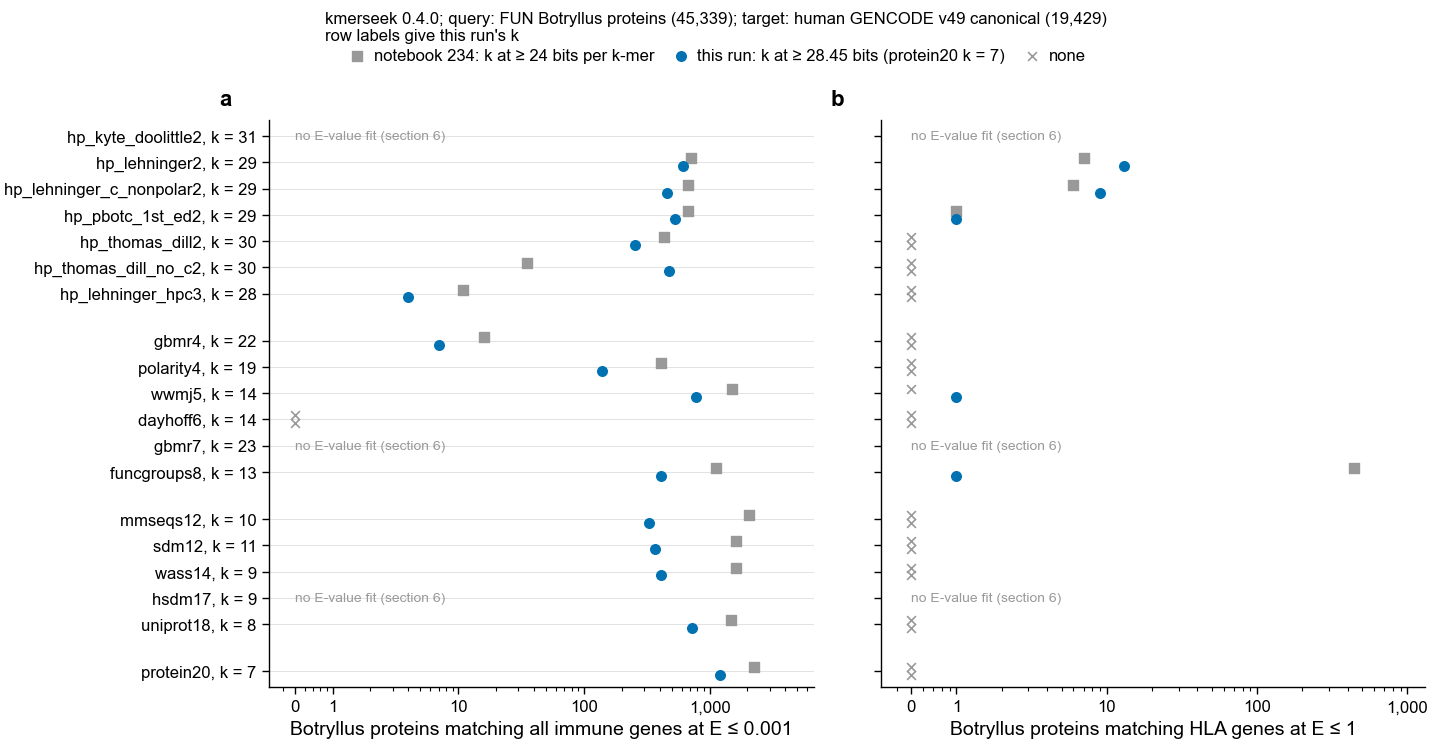

In [22]:
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 95, ncols=2, sharey=True)
for ax, gene_set, cutoff in [(axs[0], "all immune genes", STRICT_EVALUE), (axs[1], "HLA genes", 1)]:
    sub = both.filter((pl.col("gene_set") == gene_set) & (pl.col("max_evalue") == cutoff))
    for name, colour, marker, dy in [("proteins_234", pf.GREY, "s", -0.15), ("proteins_235", pf.OKABE_ITO["blue"], "o", 0.15)]:
        n = sub[name].to_numpy()
        ys = np.array([Y_OF[a] for a in sub["alphabet"]]) + dy
        ax.scatter(np.where(n > 0, n, np.nan), ys, color=colour, marker=marker, s=12, zorder=3)
        ax.scatter(np.where(n == 0, ZERO_X, np.nan), ys, color=pf.GREY, marker="x", s=10, linewidths=0.6, zorder=2)
    ax.set_xscale("log")
    top = max(sub["proteins_234"].max(), sub["proteins_235"].max(), 1) * 3
    ticks = [t for t in [1, 10, 100, 1_000, 10_000] if t <= top]
    ax.set_xlim(ZERO_X / 1.6, top)
    ax.set_xticks([ZERO_X] + ticks, ["0"] + [f"{t:,}" for t in ticks])
    ax.set_xlabel(f"Botryllus proteins matching {gene_set} at E ≤ {cutoff:g}")
    mark_no_evalues(ax, ZERO_X)
axs[0].scatter([], [], color=pf.GREY, marker="s", s=12, label="notebook 234: k at ≥ 24 bits per k-mer")
axs[0].scatter([], [], color=pf.OKABE_ITO["blue"], s=12, label="this run: k at ≥ 28.45 bits (protein20 k = 7)")
axs[0].scatter([], [], color=pf.GREY, marker="x", s=10, linewidths=0.6, label="none")
alphabet_axis(axs[0])
pf.shared_legend(fig, ncol=3, title=f"kmerseek 0.4.0; {QUERY_TARGET_LINE}\nrow labels give this run's k")
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
pf.save(fig, FIG_DIR / "235i_immune_hla_matches_24_bits_vs_protein20_k7_bits_kmerseek_alphabets")

How to read it: each row is one alphabet; grey squares are notebook 234 (k at 24 bits), blue
dots this run (k at 28.45 bits). Panel a counts Botryllus proteins with an immune match at
E ≤ 0.001; panel b counts those with an HLA match at E ≤ 1.

## Summary and conclusions

Tool for every number below: kmerseek 0.4.0, the 19 alphabets of notebook 233, each at the k
that carries at least the 28.45 bits of protein20 at k = 7 (Swiss-Prot residue frequencies),
scaled = 1, low-complexity k-mers removed. Query: 45,339 FUN Botryllus proteins. Target:
19,429 human GENCODE v49 canonical proteins.

1. **No FUN protein is an MHC-like candidate, under either rule written before the run.**
   * **16 alphabets with E-values:** 0 HLA matches at E ≤ 0.001 (notebook 234 had 17, all
     funcgroups8 matches to the HLA membrane helix). At E ≤ 1 there are 31 HLA matches from
     19 FUN proteins; 17 cover the groove or the Ig-like domain, all with E between 0.09 and
     0.99. The one with the most shared amino acids beyond chance is FUN000975_XIAP against
     the HLA-A groove (hp_lehninger2, E = 0.94): 9 of 50 positions the same, chance 0.0026
     over all positions and 0.044 over the 45 positions where both letters are in one
     class. With 17 matches tested, neither passes. FUN016327_flrt2, the 12-of-94 match of
     notebook 234, is back at E = 0.12; counted within letter classes its chance is 0.2.
   * **3 alphabets without E-values** (hp_kyte_doolittle2 k = 31, gbmr7 k = 23, hsdm17
     k = 9): their fit failed even with 19,000 calibration proteins. 263 unextended HLA
     matches; 92 have p below 0.05 / 880,891,431, and 74 of these cover the groove or
     Ig-like domain (70 from hp_kyte_doolittle2, 4 from gbmr7). None shares more amino
     acids than chance within letter classes: the smallest chance is 0.099, where step 3
     needs below 0.00071 (hp_kyte_doolittle2) or 0.0125 (gbmr7). hsdm17's 15 matches below
     the threshold are all membrane helix or signal peptide.

2. **The longer k removes most chance matches, and the funcgroups8 helix matches with them.**
   Summed over the 16 alphabets with E-values in both runs (a protein found by several
   alphabets counts once for each), immune matches at E ≤ 0.001 fall from 14,637 FUN
   proteins in notebook 234 to 6,722, and HLA matches at E ≤ 1 from 452 to 25. funcgroups8
   at k = 13 keeps one HLA match at E ≤ 1, where at k = 9 it had 438 proteins. hp_lehninger2
   and hp_lehninger_c_nonpolar2 rise at E ≤ 1 (13 and 9 proteins, from 7 and 6).

3. **Well-known immune genes are still found through domains every cell has.** 23 genes
   from the hand-picked immune families have E ≤ 0.001 in at least one alphabet. The
   strongest: PSMB8 (E = 3.5e-24, 12 alphabets), TRAF3 (1.7e-22, 12),
   PSMB10 (5.6e-17, 6) and LCK (1.1e-16, 12): proteasome, TRAF and kinase domains.

4. **Unextended matches in the alphabets with E-values add no candidate.** 4,196
   unextended HLA matches come from polarity4, gbmr4 and hp_lehninger_hpc3; 131 have p
   below the corrected threshold, 40 of them on the groove or Ig-like domain. None shares
   more amino acids than chance within letter classes (smallest chance 0.022).

5. **dayhoff6 at k = 14 gives no usable E-values.** Its fit slope is 0.014 where the closed
   form gives 0.464, and only 16 of its kept matches have E ≤ 10. It has no HLA match,
   extended or not, so it cannot hide a candidate, but its row in sections 2 to 4 is
   empty for this reason, not because Botryllus lacks immune matches.

6. **The run is sound where it can be checked.** For FUN proteins named by funannotate, the
   best immune match has the same human gene name in 39% to 54% of named proteins, over
   the 13 alphabets with at least 100 of them (protein20: 429 of 1,100).

**Verdict.** The "no MHC-like candidate from kmerseek" verdict of notebooks 232 to 234 holds
at the k of protein20 k = 7, in all 19 alphabets. Longer k removed chance matches without
bringing up a groove or Ig-like match, so further kmerseek settings are unlikely to change
this; a structure search (FoldSeek on predicted structures) is the remaining test.